# Results review v003 — no model training

This notebook reads saved experiment artifacts, draws diagnostics, and verifies the
selected CSV. Modeling code and executed fits are in
`controlled_improvements_v003.ipynb`; interpretation and the ten-idea audit are in
`INVESTIGATION_v003.md`. Run this notebook locally or on DataHub after copying the
saved metrics. It never trains, downloads data, or uploads a submission.

In [1]:
import os,json,hashlib
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display,Image
PROJECT=Path.cwd().resolve()
if not (PROJECT/'data').is_dir() and (PROJECT/'ventilator-pressure-prediction/data').is_dir():
    PROJECT=PROJECT/'ventilator-pressure-prediction'
OUT=PROJECT/'outputs/controlled_v003'
(OUT/'plot-cache'/'xdg').mkdir(parents=True,exist_ok=True)
os.environ['MPLCONFIGDIR']=str(OUT/'plot-cache')
os.environ['XDG_CACHE_HOME']=str(OUT/'plot-cache'/'xdg')
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
results=pd.read_csv(OUT/'results.csv')
display(results[['trial','split','fit_group','training_breaths','seed','validation_mae',
                 'train_diagnostic_mae','fit_seconds','best_epoch','best_iteration','termination']])

,trial,split,fit_group,training_breaths,seed,validation_mae,train_diagnostic_mae,fit_seconds,best_epoch,best_iteration,termination
0,screen_gru_width_64,A,screen,20000,20261102,0.970500,0.955680,101.999001,99.0,NaN,epoch_cap
1,screen_trees_5000,A,screen,20000,20261102,0.692632,0.492798,173.818322,NaN,5000.0,tree_cap
2,screen_gru_lr_0015,A,screen,20000,20261102,0.780586,0.759464,149.733733,99.0,NaN,epoch_cap
3,screen_gru_reference,A,screen,20000,20261102,0.837811,0.821799,0.000000,81.0,NaN,reused_prior_checkpoint
4,screen_leaves_127,A,screen,20000,20261102,0.764461,0.668762,82.302884,NaN,2500.0,tree_cap
5,screen_gru_dropout_030,A,screen,20000,20261102,0.866556,0.854527,146.025733,99.0,NaN,epoch_cap
6,screen_history_lags,A,screen,20000,20261102,0.745866,0.597031,95.609209,NaN,2500.0,tree_cap
7,B_member_s20261103,B,confirmation,54323,20261103,0.546660,0.537731,321.199238,90.0,NaN,fixed_A_budget
8,full_screen_leaves_511,A,full,61114,20261102,0.618996,0.509857,275.441835,NaN,2500.0,tree_cap
9,full_screen_gru_lr_0015,A,full,61114,20261102,0.496273,0.464049,420.809200,99.0,NaN,epoch_cap


## What changed in the controlled comparisons

All screening comparisons use the same 20,000 fitting breaths, original A
validation breaths and seed 20261102. Other history summaries stay fixed in the
lag/change test. The 61,114-breath GRU curve uses more batches per epoch; it is not
a compute-matched comparison. Training dots are endpoint errors on the same fixed
2,048 fitting breaths, with dropout disabled, rather than online training loss.

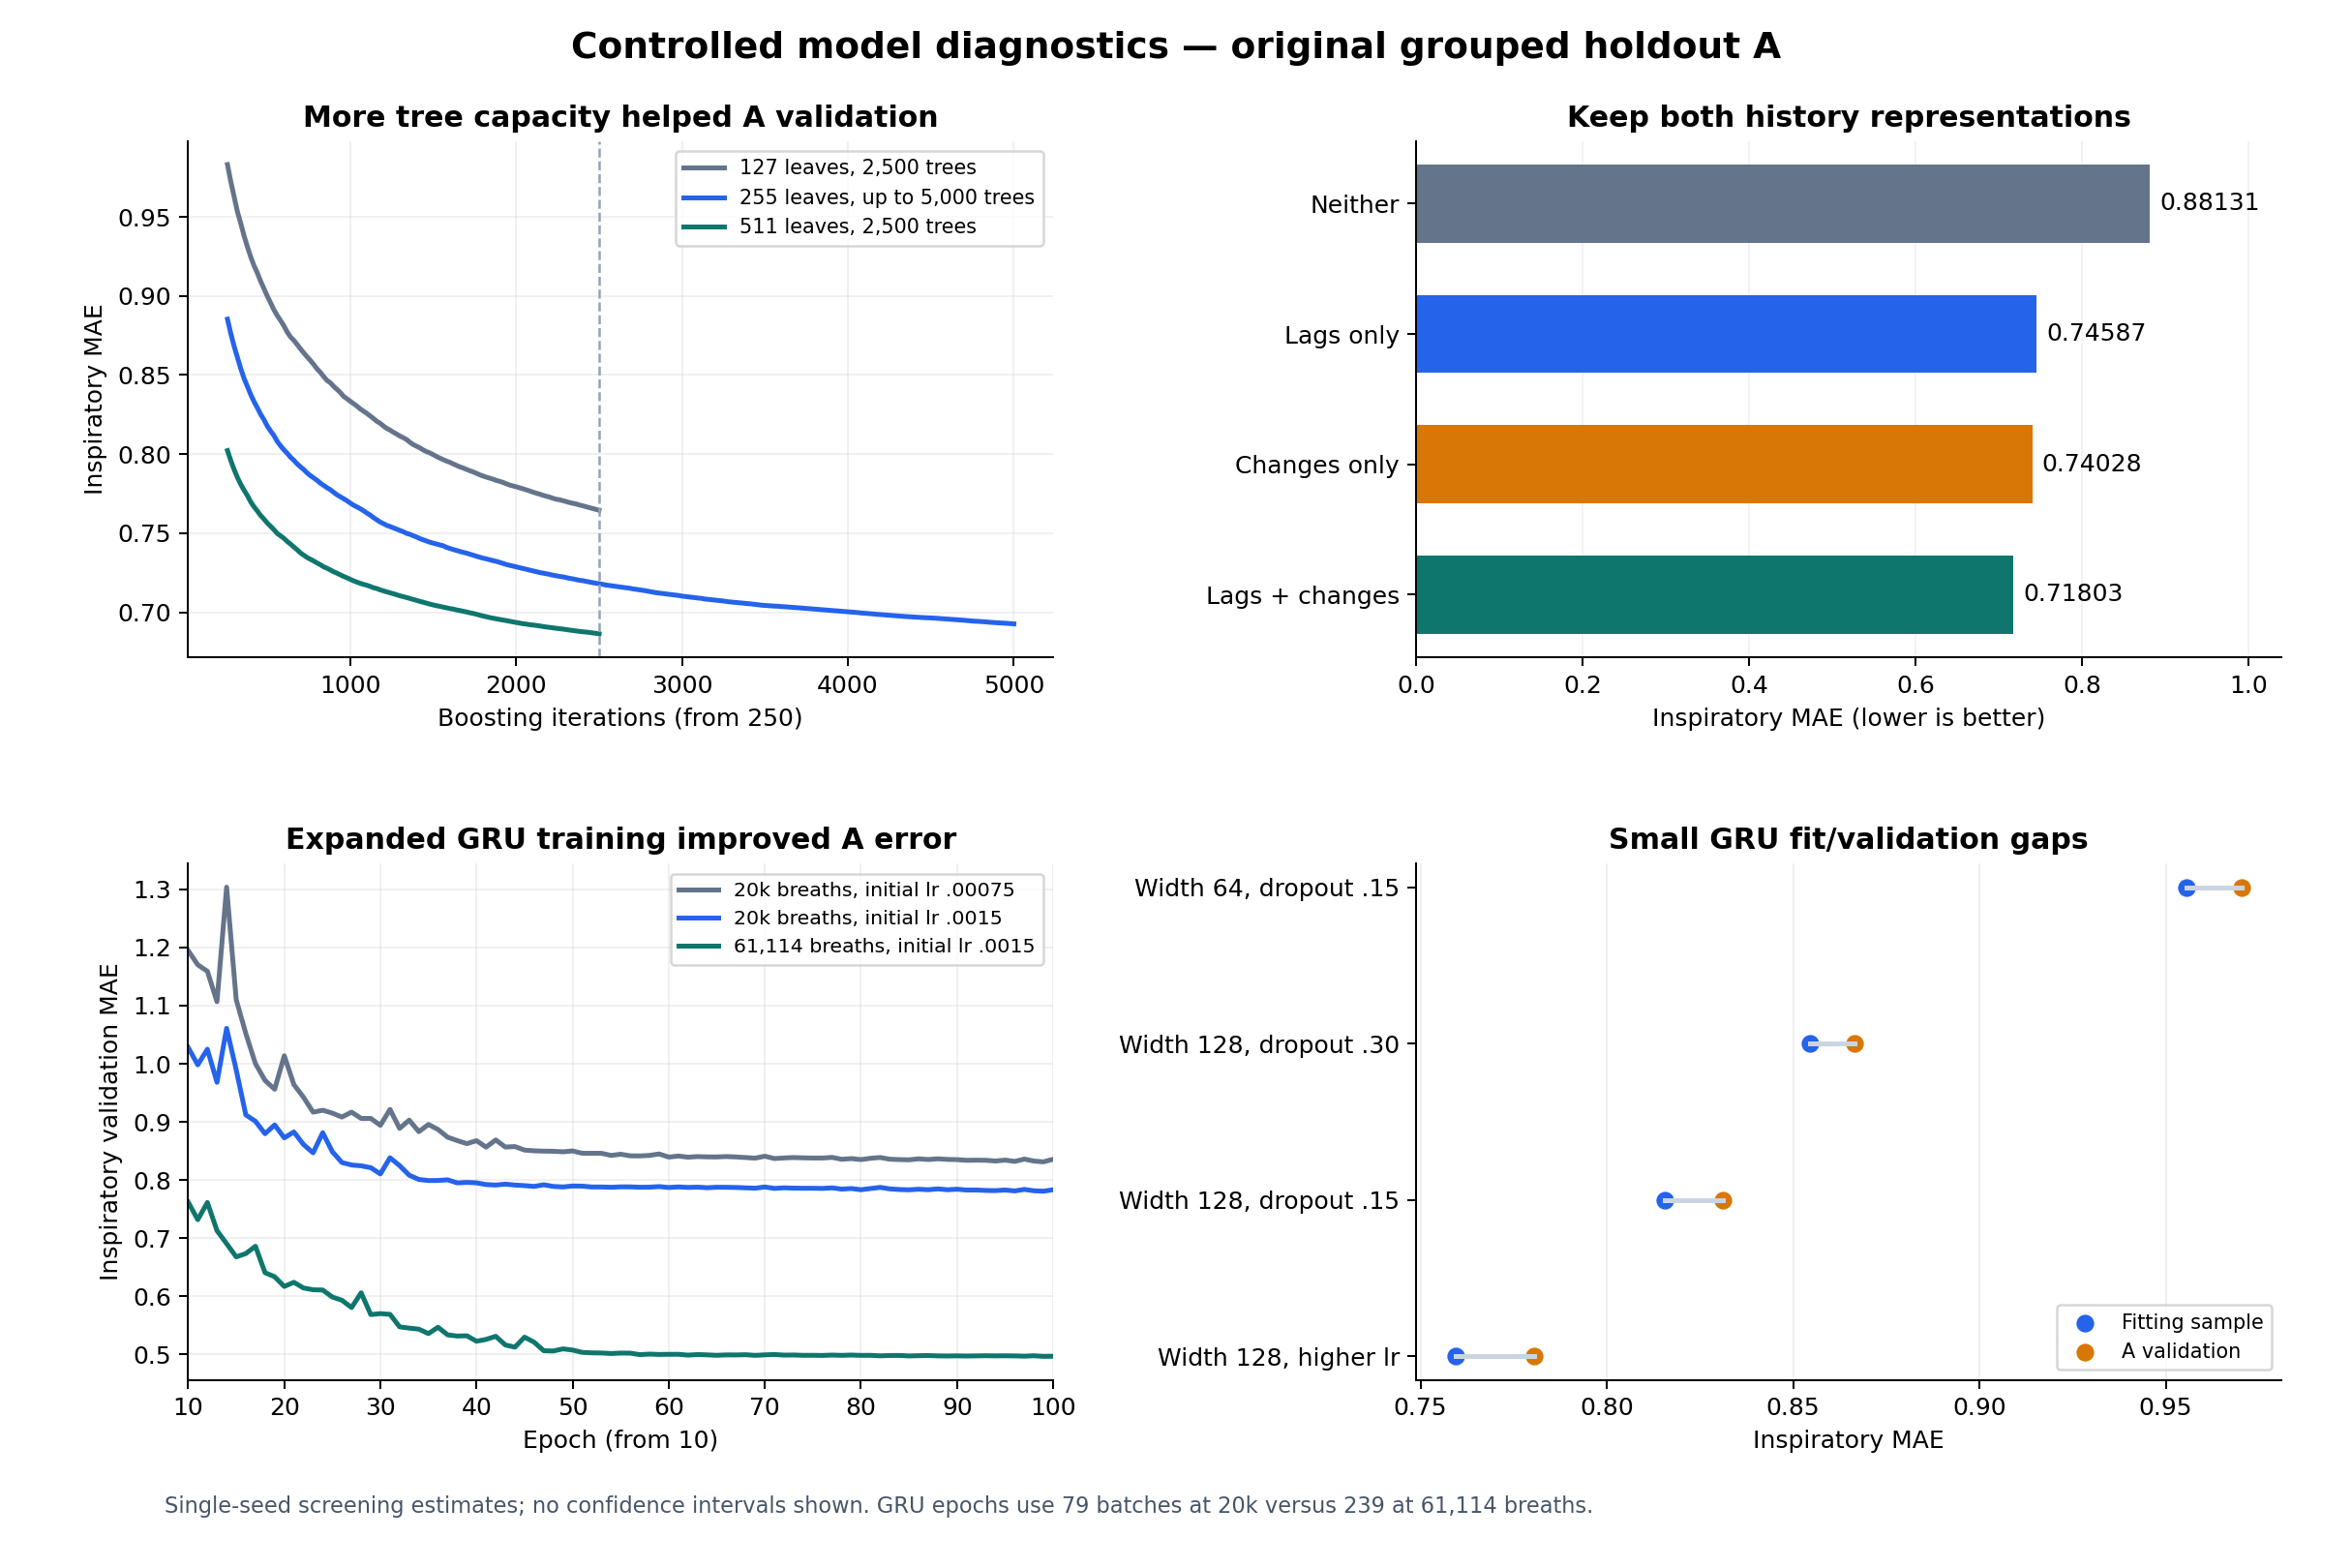

In [2]:
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,
                     'axes.spines.right':False,'axes.titleweight':'bold'})
fig,axes=plt.subplots(2,2,figsize=(13.5,9))
blue='#2563EB';teal='#0F766E';amber='#D97706';gray='#64748B'
ax=axes[0,0]
for trial,label,color in [('screen_leaves_127','127 leaves, 2,500 trees',gray),
 ('screen_trees_5000','255 leaves, up to 5,000 trees',blue),
 ('screen_leaves_511','511 leaves, 2,500 trees',teal)]:
    curve=json.loads((OUT/(trial+'_curve.json')).read_text())['validation']['l1']
    xx=np.arange(1,len(curve)+1);yy=np.asarray(curve)
    take=(xx>=250)&((xx%20==0)|(xx==len(xx)))
    ax.plot(xx[take],yy[take],label=label,color=color,lw=2)
ax.axvline(2500,color='#94A3B8',ls='--',lw=1)
ax.set(title='More tree capacity helped A validation',xlabel='Boosting iterations (from 250)',ylabel='Inspiratory MAE')
ax.grid(alpha=.18);ax.legend(fontsize=8.3)

ax=axes[0,1]
trials=['screen_history_neither','screen_history_lags','screen_history_changes','screen_tree_reference']
labels=['Neither','Lags only','Changes only','Lags + changes']
values=[float(results.loc[results.trial==t,'validation_mae'].iloc[0]) for t in trials]
ax.barh(labels,values,color=[gray,blue,amber,teal],height=.60)
ax.invert_yaxis();ax.set_xlim(0,1.04)
for i,v in enumerate(values):ax.text(v+.012,i,f'{v:.5f}',va='center',fontsize=10)
ax.set(title='Keep both history representations',xlabel='Inspiratory MAE (lower is better)')
ax.grid(axis='x',alpha=.15);ax.set_axisbelow(True)

ax=axes[1,0]
for trial,label,color in [('screen_gru_lr_floor','20k breaths, initial lr .00075',gray),
 ('screen_gru_lr_0015','20k breaths, initial lr .0015',blue),
 ('full_screen_gru_lr_0015','61,114 breaths, initial lr .0015',teal)]:
    path=OUT/(trial+'_epochs.json')
    if path.exists():
        history=json.loads(path.read_text())['epochs']
        xx=[r['epoch'] for r in history if r['epoch']>=10]
        yy=[r['validation_inspiratory_mae'] for r in history if r['epoch']>=10]
        ax.plot(xx,yy,label=label,color=color,lw=2)
ax.set(title='Expanded GRU training improved A error',xlabel='Epoch (from 10)',ylabel='Inspiratory validation MAE',xlim=(10,100))
ax.grid(alpha=.18);ax.legend(fontsize=8.2)

ax=axes[1,1]
trials=['screen_gru_width_64','screen_gru_dropout_030','screen_gru_lr_floor','screen_gru_lr_0015']
labels=['Width 64, dropout .15','Width 128, dropout .30','Width 128, dropout .15','Width 128, higher lr']
for i,(trial,label) in enumerate(zip(trials,labels)):
    r=results.loc[results.trial==trial].iloc[0]
    a=float(r.train_diagnostic_mae);b=float(r.validation_mae)
    ax.plot([a,b],[i,i],color='#CBD5E1',lw=2)
    ax.scatter(a,i,color=blue,s=40,label='Fitting sample' if i==0 else None)
    ax.scatter(b,i,color=amber,s=40,label='A validation' if i==0 else None)
ax.set_yticks(range(len(labels)),labels);ax.invert_yaxis()
ax.set(title='Small GRU fit/validation gaps',xlabel='Inspiratory MAE')
ax.grid(axis='x',alpha=.18);ax.legend(fontsize=8.3,loc='lower right')
fig.suptitle('Controlled model diagnostics — original grouped holdout A',fontsize=15,fontweight='bold',y=.98)
fig.text(.07,.035,'Single-seed screening estimates; no confidence intervals shown. GRU epochs use 79 batches at 20k versus 239 at 61,114 breaths.',fontsize=9,color='#475569')
fig.subplots_adjust(left=.08,right=.97,bottom=.12,top=.91,wspace=.42,hspace=.40)
fig.savefig(OUT/'diagnostics_v003.png',dpi=180)
fig.savefig(OUT/'diagnostics_v003.svg')
plt.close(fig)
display(Image(filename=str(OUT/'diagnostics_v003.png')))

## Seed averaging, B confirmation and the selected CSV

A and B use different holdouts and fitting sizes, so compare approaches within
each split. B models are freshly fit without B stopping feedback, using tree/epoch
budgets selected on A. B is resampling confirmation, not previously untouched data.
The predeclared eligibility rule uses B as a filter, so B is not an untouched final
test estimate. Paired bootstrap intervals resample whole breaths.

Selected approach: best_A_individual seeds: [20261102]
Verified CSV: /Users/generalclasher/Documents/dsc102/pa3/ventilator-pressure-prediction/outputs/controlled_v003/submission.csv


,approach,A_mae,B_mae,eligible
0,incumbent,0.664386,0.673307,True
1,best_A_individual,0.496273,0.522832,True
2,equal_seed_ensemble,0.505135,0.536962,False


,first,second,difference_first_minus_second,bootstrap_95_low,bootstrap_95_high,bootstrap_repeats,bootstrap_unit,negative_favors_first
0,B_member_s20261102,B_incumbent,-0.150475,-0.161369,-0.140556,1000,whole breath,True
1,B_member_s20261102,B_incumbent,-0.150475,-0.161369,-0.140556,1000,whole breath,True
2,B_equal_ensemble,B_member_s20261102,0.014130,0.011474,0.016818,1000,whole breath,True


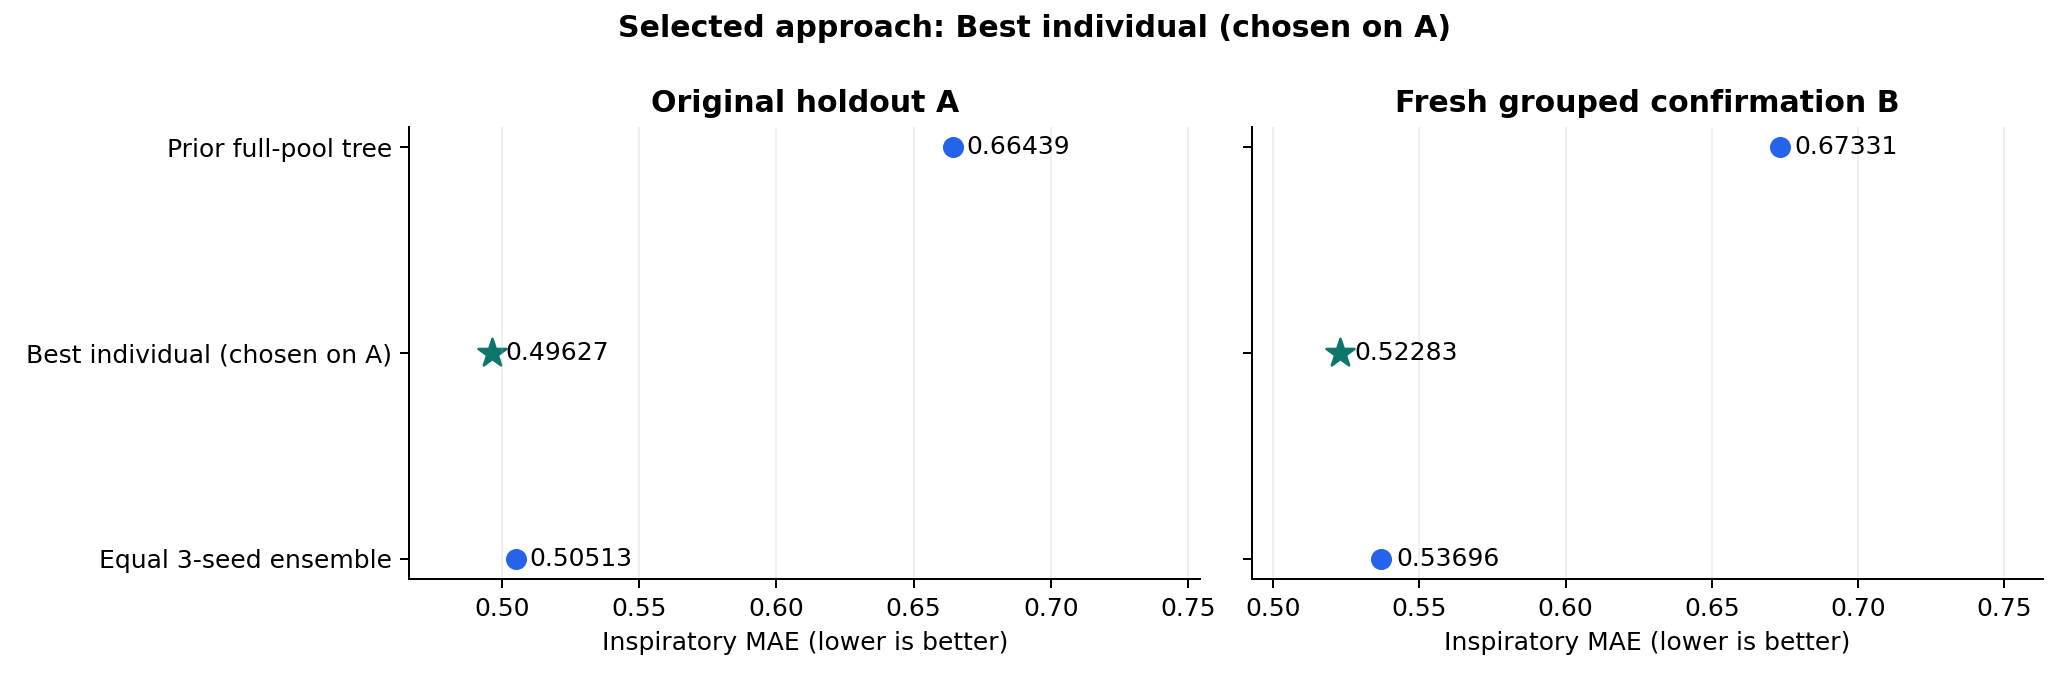

In [3]:
if (OUT/'approach_comparison.csv').exists():
    comparison=pd.read_csv(OUT/'approach_comparison.csv')
    selected=json.loads((OUT/'selected_approach.json').read_text())
    display(comparison)
    display(pd.DataFrame(json.loads((OUT/'B_paired_comparisons.json').read_text())))
    labels={'incumbent':'Prior full-pool tree','best_A_individual':'Best individual (chosen on A)',
            'equal_seed_ensemble':'Equal 3-seed ensemble'}
    fig,axes=plt.subplots(1,2,figsize=(11.5,3.8),sharey=True)
    for ax,column,title in zip(axes,['A_mae','B_mae'],['Original holdout A','Fresh grouped confirmation B']):
        for i,row in enumerate(comparison.itertuples()):
            chosen=row.approach==selected['approach'];value=getattr(row,column)
            ax.scatter(value,i,s=140 if chosen else 55,marker='*' if chosen else 'o',color=teal if chosen else blue)
            ax.text(value+.005,i,f'{value:.5f}',va='center')
        ax.set_yticks(range(len(comparison)),[labels[a] for a in comparison.approach])
        ax.set_title(title);ax.set_xlabel('Inspiratory MAE (lower is better)');ax.grid(axis='x',alpha=.2)
        ax.set_xlim(comparison[column].min()-.03,comparison[column].max()+.09)
    axes[0].invert_yaxis();fig.suptitle('Selected approach: '+labels[selected['approach']],fontweight='bold')
    fig.tight_layout()
    fig.savefig(OUT/'selection_v003.png',dpi=180);fig.savefig(OUT/'selection_v003.svg');plt.close(fig)
    display(Image(filename=str(OUT/'selection_v003.png')))
    submission=pd.read_csv(OUT/'submission.csv')
    sample_ids=pd.read_csv(PROJECT/'data/sample_submission.csv',usecols=['id']).id.to_numpy()
    assert list(submission.columns)==['id','pressure'] and len(submission)==603600
    assert np.array_equal(submission.id.to_numpy(),sample_ids) and np.isfinite(submission.pressure).all()
    assert hashlib.sha256((OUT/'submission.csv').read_bytes()).hexdigest()==selected['submission_sha256']
    print('Selected approach:',selected['approach'],'seeds:',selected['model_seeds'])
    print('Verified CSV:',OUT/'submission.csv')
else:
    print('Seed averaging and B confirmation are still running. No final v003 CSV is selected yet.')